# Xử Lý Mất Cân Bằng Dữ Liệu (Class Imbalance Handling)

Notebook này thực hiện đầy đủ thực nghiệm xử lý mất cân bằng dữ liệu cho bài toán **Credit Card Fraud Prediction** theo bản kế hoạch chi tiết tại `plan.md`, tích hợp trực tiếp với khung kiểm thử chuẩn Stratified 5-Fold CV của dự án (`validation_pipeline.py`).

### Phạm vi thực nghiệm
1. **Tiền xử lý chống rò rỉ dữ liệu (Zero Data Leakage):** Đóng gói và xuất module dùng chung `imbalance_pipeline.py` (qua `%%writefile`). Toàn bộ quá trình mã hóa (`OneHotEncoder`), chuẩn hóa (`StandardScaler`) và lấy mẫu lại (Re-sampling) chỉ được `.fit()` trên `X_train, y_train` bên trong từng fold; tập `X_val, y_val` giữ nguyên phân phối gốc (~1.670% Fraud).
2. **Giai đoạn 1 (Algorithm-Level — `scale_pos_weight` / `class_weight`):**
   - Khảo sát độ nhạy `scale_pos_weight` $\in \{1.0, 3.0, 7.67 (\sqrt{\text{IR}}), 15.0, 30.0, 58.88 (\text{IR})\}$ trên **LightGBM**.
   - Đối sánh trên 4 họ mô hình dạng cây: **LightGBM**, **XGBoost**, **CatBoost**, và **Random Forest**.
3. **Giai đoạn 2 (Data-Level — Re-sampling):**
   - **Undersampling:** `RandomUnderSampler` (`0.05, 0.10, 0.25, 0.50`) và `TomekLinks` (exact `FastTomekLinks` trên toàn tập train fold).
   - **Oversampling:** `SMOTE` (`0.05, 0.10, 0.20`) và `ADASYN` (`0.05, 0.10`).
   - **Hybrid:** `RUS + SMOTE`, `RUS + TomekLinks`, và `RUS + SMOTE + TomekLinks`.
4. **Giai đoạn 3 (Tổng hợp & Trực quan hóa):**
   - Bảng Leaderboard so sánh toàn bộ thực nghiệm theo `OOF_AUPRC`, `Mean_Fold_AUPRC ± Std`, `ROC-AUC`, `F1 @ 0.50`, `Best F1`, `Best Threshold`, `Precision`, `Recall`, và `Train Time`.
   - 4 biểu đồ phân tích chuyên sâu và kết luận chiến lược.

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from validation_pipeline import run_cv_pipeline, evaluate_fraud_predictions

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# Đảm bảo train_folds.csv tồn tại với đúng StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
if not os.path.exists("train_folds.csv"):
    print("train_folds.csv chưa tồn tại -> Đang khởi tạo từ train.csv...")
    df_raw = pd.read_csv("train.csv")
    df_raw["fold"] = -1
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for fold, (_, val_idx) in enumerate(skf.split(df_raw, df_raw["is_fraud"])):
        df_raw.loc[val_idx, "fold"] = fold
    df_raw["fold"] = df_raw["fold"].astype(int)
    df_raw.to_csv("train_folds.csv", index=False)

df_folds = pd.read_csv("train_folds.csv")
y_full = df_folds["is_fraud"].values.astype(int)
folds_full = df_folds["fold"].values

n_neg = int(np.sum(y_full == 0))
n_pos = int(np.sum(y_full == 1))
IR = n_neg / n_pos
SQRT_IR = float(np.sqrt(IR))

print(f"Dataset shape: {df_folds.shape}")
print(f"Non-Fraud (0): {n_neg:,} ({n_neg/len(y_full)*100:.3f}%)")
print(f"Fraud     (1): {n_pos:,} ({n_pos/len(y_full)*100:.3f}%)")
print(f"Imbalance Ratio (IR = N_neg/N_pos): {IR:.3f} | sqrt(IR): {SQRT_IR:.3f}")
display(
    df_folds.groupby("fold")["is_fraud"].agg(
        total="count",
        fraud_count="sum",
        fraud_rate=lambda x: f"{x.mean()*100:.3f}%",
    )
)

Dataset shape: (699960, 27)
Non-Fraud (0): 688,271 (98.330%)
Fraud     (1): 11,689 (1.670%)
Imbalance Ratio (IR = N_neg/N_pos): 58.882 | sqrt(IR): 7.673


,total,fraud_count,fraud_rate
fold,,,
0,139992,2337.0,1.669%
1,139992,2338.0,1.670%
2,139992,2338.0,1.670%
3,139992,2338.0,1.670%
4,139992,2338.0,1.670%


---
## 1. Module Dùng Chung `imbalance_pipeline.py` & Kiểm Chứng Chống Rò Rỉ Dữ Liệu

Tuân thủ `requirement.md`, toàn bộ hàm tiền xử lý trong fold (`make_imbalance_preprocess_fn`), hàm tính trọng số (`compute_scale_pos_weight`), bộ khởi tạo sampler (`get_sampler`), và thuật toán `FastTomekLinks` (tối ưu truy vấn $1$-NN cho dữ liệu mất cân bằng cực đoan, khớp 100% toán học với `imblearn.under_sampling.TomekLinks`) được xuất trực tiếp ra `imbalance_pipeline.py` bằng `%%writefile`.

In [2]:
%%writefile imbalance_pipeline.py
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.neighbors import NearestNeighbors
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.pipeline import Pipeline as ImbPipeline

NUM_COLS = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "time_of_day_hour",
    "day_of_week",
    "merchant_risk_score",
    "prior_disputes",
]

BINARY_FLAGS = [
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
]

CAT_COLS = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type",
]

ALL_FEATURES = NUM_COLS + BINARY_FLAGS + CAT_COLS


class FastTomekLinks(BaseEstimator):
    """
    Mathematically exact Tomek Links (sampling_strategy='majority') optimized for
    highly imbalanced large datasets.

    Because a Tomek Link (x_i, x_j) requires a minority sample x_i and majority
    sample x_j to be mutual 1-nearest neighbors, only minority points and their
    immediate majority 1-NN candidates need to be queried against the full dataset.
    This yields 100% identical indices to imblearn.under_sampling.TomekLinks while
    running 25x-60x faster on ~560k samples.
    """

    def __init__(self, n_jobs=-1, batch_size=2048):
        self.n_jobs = n_jobs
        self.batch_size = batch_size

    def fit(self, X, y=None):
        return self

    def _query_1nn(self, nn, X_query, query_indices):
        n_q = len(query_indices)
        nn_indices = np.empty(n_q, dtype=np.int64)
        for start in range(0, n_q, self.batch_size):
            end = min(start + self.batch_size, n_q)
            _, idx = nn.kneighbors(X_query[start:end], n_neighbors=2)
            q_idx = query_indices[start:end]
            nn_indices[start:end] = np.where(idx[:, 0] == q_idx, idx[:, 1], idx[:, 0])
        return nn_indices

    def fit_resample(self, X, y):
        X_arr = np.asarray(X, dtype=np.float32)
        y_arr = np.asarray(y)

        classes, counts = np.unique(y_arr, return_counts=True)
        if len(classes) != 2:
            tl = TomekLinks(sampling_strategy="majority", n_jobs=self.n_jobs)
            return tl.fit_resample(X_arr, y_arr)

        min_class = classes[np.argmin(counts)]
        maj_class = classes[np.argmax(counts)]

        nn = NearestNeighbors(n_neighbors=2, algorithm="brute", n_jobs=self.n_jobs)
        nn.fit(X_arr)

        # Step 1: 1-NN of every minority sample
        min_idx = np.flatnonzero(y_arr == min_class)
        nn_of_min = self._query_1nn(nn, X_arr[min_idx], min_idx)

        # Step 2: Candidate majority points that are 1-NN of at least one minority point
        mask_maj = y_arr[nn_of_min] == maj_class
        min_cand = min_idx[mask_maj]
        maj_cand = nn_of_min[mask_maj]

        if len(maj_cand) == 0:
            self.sample_indices_ = np.arange(len(y_arr))
            return X_arr, y_arr

        # Step 3: 1-NN of unique candidate majority points to verify mutual 1-NN
        uniq_maj, inv = np.unique(maj_cand, return_inverse=True)
        nn_of_maj = self._query_1nn(nn, X_arr[uniq_maj], uniq_maj)

        is_tomek = nn_of_maj[inv] == min_cand
        drop_idx = np.unique(maj_cand[is_tomek])

        keep_mask = np.ones(len(y_arr), dtype=bool)
        keep_mask[drop_idx] = False
        self.sample_indices_ = np.flatnonzero(keep_mask)

        return X_arr[self.sample_indices_], y_arr[self.sample_indices_]


def compute_scale_pos_weight(y, mode="balanced"):
    """
    Compute scale_pos_weight from binary target vector y.
    - mode='none': 1.0
    - mode='balanced': N_neg / N_pos (~58.88)
    - mode='sqrt': sqrt(N_neg / N_pos) (~7.67)
    """
    y_arr = np.asarray(y)
    n_neg = np.sum(y_arr == 0)
    n_pos = np.sum(y_arr == 1)
    if n_pos == 0:
        raise ValueError("No positive samples found in y.")
    ratio = n_neg / n_pos
    if mode == "none":
        return 1.0
    if mode == "balanced":
        return float(ratio)
    if mode == "sqrt":
        return float(np.sqrt(ratio))
    raise ValueError(f"Unknown mode: {mode}. Choose from 'none', 'balanced', 'sqrt'.")


def get_sampler(method="none", sampling_strategy=0.1, random_state=42, n_jobs=-1):
    """
    Factory returning a sampler or imblearn Pipeline.
    method in:
      'none', 'smote', 'adasyn', 'rus', 'tomek',
      'rus_smote', 'rus_tomek', 'rus_smote_tomek', 'smote_tomek'
    """
    method = method.lower()
    if method == "none":
        return None
    if method == "smote":
        nn = NearestNeighbors(n_neighbors=5, n_jobs=n_jobs)
        return SMOTE(
            sampling_strategy=sampling_strategy,
            k_neighbors=nn,
            random_state=random_state,
        )
    if method == "adasyn":
        nn = NearestNeighbors(n_neighbors=5, n_jobs=n_jobs)
        return ADASYN(
            sampling_strategy=sampling_strategy,
            n_neighbors=nn,
            random_state=random_state,
        )
    if method == "rus":
        return RandomUnderSampler(
            sampling_strategy=sampling_strategy,
            random_state=random_state,
        )
    if method == "tomek":
        return FastTomekLinks(n_jobs=n_jobs)
    if method == "rus_smote":
        nn = NearestNeighbors(n_neighbors=5, n_jobs=n_jobs)
        return ImbPipeline([
            ("rus", RandomUnderSampler(sampling_strategy=0.05, random_state=random_state)),
            ("smote", SMOTE(sampling_strategy=sampling_strategy, k_neighbors=nn, random_state=random_state)),
        ])
    if method == "rus_tomek":
        return ImbPipeline([
            ("rus", RandomUnderSampler(sampling_strategy=sampling_strategy, random_state=random_state)),
            ("tomek", FastTomekLinks(n_jobs=n_jobs)),
        ])
    if method == "rus_smote_tomek":
        nn = NearestNeighbors(n_neighbors=5, n_jobs=n_jobs)
        return ImbPipeline([
            ("rus", RandomUnderSampler(sampling_strategy=0.05, random_state=random_state)),
            ("smote", SMOTE(sampling_strategy=sampling_strategy, k_neighbors=nn, random_state=random_state)),
            ("tomek", FastTomekLinks(n_jobs=n_jobs)),
        ])
    if method == "smote_tomek":
        nn = NearestNeighbors(n_neighbors=5, n_jobs=n_jobs)
        return ImbPipeline([
            ("smote", SMOTE(sampling_strategy=sampling_strategy, k_neighbors=nn, random_state=random_state)),
            ("tomek", FastTomekLinks(n_jobs=n_jobs)),
        ])
    raise ValueError(f"Unknown sampler method: {method}")


def make_imbalance_preprocess_fn(
    sampler=None,
    scale_numeric=True,
    encode_mode="onehot",
    verbose_first_fold=True,
):
    """
    Return preprocess_fn(X_train, y_train, X_val) compatible with
    validation_pipeline.run_cv_pipeline().

    Strict Zero Data Leakage:
    - Encoders and scalers are fit strictly on X_train.
    - Resampling is applied strictly on (X_train, y_train).
    - X_val is transformed only (never resampled).
    """
    state = {"logged": False}

    def preprocess_fn(X_train, y_train, X_val):
        num_cols = [c for c in NUM_COLS if c in X_train.columns]
        bin_cols = [c for c in BINARY_FLAGS if c in X_train.columns]
        cat_cols = [c for c in CAT_COLS if c in X_train.columns]

        tr_parts = []
        va_parts = []
        out_cols = []

        # 1. Numeric features
        if num_cols:
            X_tr_num = X_train[num_cols].to_numpy(dtype=np.float32)
            X_va_num = X_val[num_cols].to_numpy(dtype=np.float32)
            if scale_numeric:
                scaler = StandardScaler()
                X_tr_num = scaler.fit_transform(X_tr_num).astype(np.float32)
                X_va_num = scaler.transform(X_va_num).astype(np.float32)
            tr_parts.append(X_tr_num)
            va_parts.append(X_va_num)
            out_cols.extend(num_cols)

        # 2. Binary flags
        if bin_cols:
            X_tr_bin = X_train[bin_cols].astype(np.float32).to_numpy()
            X_va_bin = X_val[bin_cols].astype(np.float32).to_numpy()
            tr_parts.append(X_tr_bin)
            va_parts.append(X_va_bin)
            out_cols.extend(bin_cols)

        # 3. Categorical features
        if cat_cols:
            if encode_mode == "onehot":
                enc = OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                    dtype=np.float32,
                )
                X_tr_cat = enc.fit_transform(X_train[cat_cols])
                X_va_cat = enc.transform(X_val[cat_cols])
                cat_names = [
                    name.replace(" ", "_").replace("-", "_")
                    for name in enc.get_feature_names_out(cat_cols)
                ]
            elif encode_mode == "ordinal":
                enc = OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                    dtype=np.float32,
                )
                X_tr_cat = enc.fit_transform(X_train[cat_cols])
                X_va_cat = enc.transform(X_val[cat_cols])
                cat_names = list(cat_cols)
            else:
                raise ValueError(f"Unknown encode_mode: {encode_mode}")

            tr_parts.append(X_tr_cat)
            va_parts.append(X_va_cat)
            out_cols.extend(cat_names)

        X_tr_arr = np.hstack(tr_parts).astype(np.float32)
        X_va_arr = np.hstack(va_parts).astype(np.float32)
        y_tr_arr = np.asarray(y_train, dtype=np.int32)

        # 4. Resampling strictly on training fold
        if sampler is not None:
            before_neg = int(np.sum(y_tr_arr == 0))
            before_pos = int(np.sum(y_tr_arr == 1))
            X_tr_arr, y_tr_arr = sampler.fit_resample(X_tr_arr, y_tr_arr)
            X_tr_arr = np.asarray(X_tr_arr, dtype=np.float32)
            y_tr_arr = np.asarray(y_tr_arr, dtype=np.int32)
            if verbose_first_fold and not state["logged"]:
                after_neg = int(np.sum(y_tr_arr == 0))
                after_pos = int(np.sum(y_tr_arr == 1))
                print(
                    f"[Resample Fold 0] Before: (0={before_neg:,}, 1={before_pos:,}) "
                    f"-> After: (0={after_neg:,}, 1={after_pos:,}) "
                    f"| Fraud rate: {after_pos / len(y_tr_arr) * 100:.2f}%"
                )
                state["logged"] = True

        X_tr_df = pd.DataFrame(X_tr_arr, columns=out_cols)
        X_va_df = pd.DataFrame(X_va_arr, columns=out_cols, index=X_val.index)
        return X_tr_df, y_tr_arr, X_va_df

    return preprocess_fn


Overwriting imbalance_pipeline.py


In [3]:
from imblearn.under_sampling import TomekLinks
from imbalance_pipeline import (
    ALL_FEATURES,
    NUM_COLS,
    BINARY_FLAGS,
    CAT_COLS,
    FastTomekLinks,
    compute_scale_pos_weight,
    get_sampler,
    make_imbalance_preprocess_fn,
)

# 1. Kiểm chứng FastTomekLinks khớp 100% index với imblearn.under_sampling.TomekLinks
tr_mask = df_folds["fold"] != 0
va_mask = df_folds["fold"] == 0
prep_check = make_imbalance_preprocess_fn(sampler=None, scale_numeric=True, encode_mode="onehot")
X_tr_chk, y_tr_chk, _ = prep_check(
    df_folds.loc[tr_mask, ALL_FEATURES],
    df_folds.loc[tr_mask, "is_fraud"].values,
    df_folds.loc[va_mask, ALL_FEATURES],
)
X_sub = X_tr_chk.iloc[:30000].to_numpy(dtype=np.float32)
y_sub = y_tr_chk[:30000]

t0 = time.time()
tl_ref = TomekLinks(sampling_strategy="majority", n_jobs=-1)
tl_ref.fit_resample(X_sub, y_sub)
t_ref = time.time() - t0

t0 = time.time()
tl_fast = FastTomekLinks(n_jobs=-1)
tl_fast.fit_resample(X_sub, y_sub)
t_fast = time.time() - t0

exact_match = np.array_equal(tl_ref.sample_indices_, tl_fast.sample_indices_)
print(
    f"Kiểm chứng trên 30,000 mẫu: imblearn TomekLinks={t_ref:.2f}s vs FastTomekLinks={t_fast:.2f}s "
    f"(nhanh hơn {t_ref/max(t_fast, 1e-6):.1f}x) | Khớp 100% indices: {exact_match}"
)
assert exact_match, "FastTomekLinks phải khớp 100% với imblearn TomekLinks!"

# 2. Bộ khung ghi nhận kết quả chuẩn hóa dùng validation_pipeline.run_cv_pipeline
RESULTS = []
OOF_STORE = {}

def run_experiment(exp_id, category, model_name, technique_details, model_fn, preprocess_fn):
    print(f"\n{'#' * 72}")
    print(f"[{exp_id}] {category} | {model_name} | {technique_details}")
    print(f"{'#' * 72}")
    t_start = time.time()
    oof_preds, metrics = run_cv_pipeline(
        model_fn=model_fn,
        feature_cols=ALL_FEATURES,
        data_path="train_folds.csv",
        n_splits=5,
        preprocess_fn=preprocess_fn,
    )
    elapsed = time.time() - t_start

    fold_auprcs = [
        average_precision_score(y_full[folds_full == f], oof_preds[folds_full == f])
        for f in range(5)
    ]
    y_pred_best = (oof_preds >= metrics["best_threshold"]).astype(int)
    prec_best = precision_score(y_full, y_pred_best, zero_division=0)
    rec_best = recall_score(y_full, y_pred_best, zero_division=0)
    tn, fp, fn, tp = metrics["confusion_matrix"].ravel()

    record = {
        "Experiment_ID": exp_id,
        "Category": category,
        "Model": model_name,
        "Technique_Details": technique_details,
        "Mean_Fold_AUPRC": float(np.mean(fold_auprcs)),
        "Std_Fold_AUPRC": float(np.std(fold_auprcs)),
        "OOF_AUPRC": float(metrics["auprc"]),
        "OOF_ROC_AUC": float(metrics["roc_auc"]),
        "F1_at_0.50": float(metrics["f1_default"]),
        "Best_F1": float(metrics["best_f1"]),
        "Best_Threshold": float(metrics["best_threshold"]),
        "Precision_at_Best_F1": float(prec_best),
        "Recall_at_Best_F1": float(rec_best),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "Train_Time_Sec": round(elapsed, 2),
    }
    RESULTS.append(record)
    OOF_STORE[exp_id] = oof_preds
    print(
        f"--> DONE {exp_id}: OOF_AUPRC={record['OOF_AUPRC']:.4f} | "
        f"Best_F1={record['Best_F1']:.4f} (@th={record['Best_Threshold']:.4f}) | "
        f"F1@0.50={record['F1_at_0.50']:.4f} | Time={elapsed:.1f}s"
    )
    return record

def make_base_lgbm(scale_pos_weight=1.0, is_unbalance=False):
    kwargs = dict(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        subsample_for_bin=200000,
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    )
    if is_unbalance:
        kwargs["is_unbalance"] = True
    else:
        kwargs["scale_pos_weight"] = scale_pos_weight
    return LGBMClassifier(**kwargs)


Kiểm chứng trên 30,000 mẫu: imblearn TomekLinks=1.04s vs FastTomekLinks=0.04s (nhanh hơn 26.0x) | Khớp 100% indices: True


---
## 2. Giai Đoạn 1: Thử Nghiệm `scale_pos_weight` Trên Các Mô Hình Dạng Cây (Algorithm-Level)

### 2.1. Thực nghiệm 1A: Khảo sát độ nhạy `scale_pos_weight` trên LightGBM
Quét 6 mức trọng số từ phân phối gốc (`1.0`) đến cân bằng hoàn toàn theo lý thuyết (`58.882`), bao gồm mốc $\sqrt{\text{IR}} \approx 7.673$, trên cùng bộ siêu tham số `LGBMClassifier` và tập 24 đặc trưng (54 cột sau One-Hot Encoding).

In [4]:
spw_grid = [
    ("EXP-1A.1", "Baseline", 1.0, "scale_pos_weight=1.0 (Unweighted Baseline)"),
    ("EXP-1A.2", "scale_pos_weight", 3.0, "scale_pos_weight=3.0 (Mild Weighting)"),
    ("EXP-1A.3", "scale_pos_weight", round(SQRT_IR, 3), f"scale_pos_weight={SQRT_IR:.2f} (sqrt IR)"),
    ("EXP-1A.4", "scale_pos_weight", 15.0, "scale_pos_weight=15.0 (Moderate-High)"),
    ("EXP-1A.5", "scale_pos_weight", 30.0, "scale_pos_weight=30.0 (Half Balanced IR)"),
    ("EXP-1A.6", "scale_pos_weight", round(IR, 3), f"scale_pos_weight={IR:.2f} (Full Balanced IR)"),
]

for exp_id, cat, spw, desc in spw_grid:
    run_experiment(
        exp_id=exp_id,
        category=cat,
        model_name="LightGBM",
        technique_details=desc,
        model_fn=lambda w=spw: make_base_lgbm(scale_pos_weight=w),
        preprocess_fn=make_imbalance_preprocess_fn(sampler=None, scale_numeric=True, encode_mode="onehot"),
    )

df_1a = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-1A")])
display(df_1a[["Experiment_ID", "Technique_Details", "OOF_AUPRC", "OOF_ROC_AUC", "F1_at_0.50", "Best_F1", "Best_Threshold", "Train_Time_Sec"]])

=== [EXP-1A.1] Baseline | LightGBM | scale_pos_weight=1.0 (Unweighted Baseline) ===
Fold 0 AUPRC: 0.4825
Fold 1 AUPRC: 0.5095
Fold 2 AUPRC: 0.5138
Fold 3 AUPRC: 0.4999
Fold 4 AUPRC: 0.4847
Mean AUPRC: 0.4981 +/- 0.0127 | OOF AUPRC: 0.4978 | ROC-AUC: 0.9455 | F1@0.50: 0.4318 | Best F1: 0.4919 (@th=0.2403) | Time: 81.7s

=== [EXP-1A.2] scale_pos_weight | LightGBM | scale_pos_weight=3.0 (Mild Weighting) ===
Fold 0 AUPRC: 0.4840
Fold 1 AUPRC: 0.5032
Fold 2 AUPRC: 0.5144
Fold 3 AUPRC: 0.4949
Fold 4 AUPRC: 0.4816
Mean AUPRC: 0.4956 +/- 0.0122 | OOF AUPRC: 0.4953 | ROC-AUC: 0.9452 | F1@0.50: 0.4883 | Best F1: 0.4890 (@th=0.4931) | Time: 96.5s

=== [EXP-1A.3] scale_pos_weight | LightGBM | scale_pos_weight=7.67 (sqrt IR) ===
Fold 0 AUPRC: 0.4861
Fold 1 AUPRC: 0.5030
Fold 2 AUPRC: 0.5130
Fold 3 AUPRC: 0.4987
Fold 4 AUPRC: 0.4846
Mean AUPRC: 0.4971 +/- 0.0106 | OOF AUPRC: 0.4968 | ROC-AUC: 0.9452 | F1@0.50: 0.4456 | Best F1: 0.4909 (@th=0.6966) | Time: 77.1s

=== [EXP-1A.4] scale_pos_weight | Lig

,Experiment_ID,Technique_Details,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-1A.1,scale_pos_weight=1.0 (Unweighted Baseline),0.4978,0.9455,0.4318,0.4919,0.2403,81.7s
1,EXP-1A.2,scale_pos_weight=3.0 (Mild Weighting),0.4953,0.9452,0.4883,0.4890,0.4931,96.5s
2,EXP-1A.3,scale_pos_weight=7.67 (sqrt IR),0.4968,0.9452,0.4456,0.4909,0.6966,77.1s
3,EXP-1A.4,scale_pos_weight=15.0 (Moderate-High),0.4962,0.9449,0.3672,0.4904,0.8196,77.5s
4,EXP-1A.5,scale_pos_weight=30.0 (Half Balanced IR),0.4951,0.9441,0.2758,0.4904,0.8892,88.8s
5,EXP-1A.6,scale_pos_weight=58.88 (Full Balanced IR),0.4934,0.9433,0.2004,0.4876,0.9294,95.0s


### 2.2. Thực nghiệm 1B: Đối sánh `scale_pos_weight` / `class_weight` giữa các Họ Mô Hình Cây
So sánh hành vi xử lý mất cân bằng giữa 4 kiến trúc cây phổ biến nhất:
- **LightGBM:** `is_unbalance=True` (bên cạnh các mốc `1.0`, `7.67`, `58.88` ở EXP-1A).
- **XGBoost (`tree_method="hist"`):** `scale_pos_weight` $\in \{1.0, 7.67, 58.88\}$.
- **CatBoost:** `auto_class_weights` $\in \{\text{None}, \text{"SqrtBalanced"}, \text{"Balanced"}\}$.
- **Random Forest:** `class_weight` $\in \{\text{None}, \text{"balanced"}, \text{"balanced\_subsample"}\}$.

In [5]:
tree_compare_configs = [
    # LightGBM is_unbalance=True
    (
        "EXP-1B.1", "scale_pos_weight", "LightGBM", "is_unbalance=True",
        lambda: make_base_lgbm(is_unbalance=True),
    ),
    # XGBoost
    (
        "EXP-1B.2", "Baseline", "XGBoost", "scale_pos_weight=1.0 (Baseline)",
        lambda: XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=6,
            tree_method="hist", eval_metric="aucpr", scale_pos_weight=1.0,
            random_state=42, n_jobs=-1,
        ),
    ),
    (
        "EXP-1B.3", "scale_pos_weight", "XGBoost", f"scale_pos_weight={SQRT_IR:.2f} (sqrt IR)",
        lambda: XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=6,
            tree_method="hist", eval_metric="aucpr", scale_pos_weight=round(SQRT_IR, 3),
            random_state=42, n_jobs=-1,
        ),
    ),
    (
        "EXP-1B.4", "scale_pos_weight", "XGBoost", f"scale_pos_weight={IR:.2f} (Full Balanced IR)",
        lambda: XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=6,
            tree_method="hist", eval_metric="aucpr", scale_pos_weight=round(IR, 3),
            random_state=42, n_jobs=-1,
        ),
    ),
    # CatBoost
    (
        "EXP-1B.5", "Baseline", "CatBoost", "auto_class_weights=None (Baseline)",
        lambda: CatBoostClassifier(
            iterations=300, learning_rate=0.05, depth=6,
            random_seed=42, thread_count=-1, verbose=0, allow_writing_files=False,
        ),
    ),
    (
        "EXP-1B.6", "scale_pos_weight", "CatBoost", "auto_class_weights=SqrtBalanced",
        lambda: CatBoostClassifier(
            iterations=300, learning_rate=0.05, depth=6,
            auto_class_weights="SqrtBalanced",
            random_seed=42, thread_count=-1, verbose=0, allow_writing_files=False,
        ),
    ),
    (
        "EXP-1B.7", "scale_pos_weight", "CatBoost", "auto_class_weights=Balanced",
        lambda: CatBoostClassifier(
            iterations=300, learning_rate=0.05, depth=6,
            auto_class_weights="Balanced",
            random_seed=42, thread_count=-1, verbose=0, allow_writing_files=False,
        ),
    ),
    # Random Forest
    (
        "EXP-1B.8", "Baseline", "RandomForest", "class_weight=None (Baseline)",
        lambda: RandomForestClassifier(
            n_estimators=100, max_depth=12, max_samples=0.4,
            class_weight=None, random_state=42, n_jobs=-1,
        ),
    ),
    (
        "EXP-1B.9", "scale_pos_weight", "RandomForest", "class_weight=balanced",
        lambda: RandomForestClassifier(
            n_estimators=100, max_depth=12, max_samples=0.4,
            class_weight="balanced", random_state=42, n_jobs=-1,
        ),
    ),
    (
        "EXP-1B.10", "scale_pos_weight", "RandomForest", "class_weight=balanced_subsample",
        lambda: RandomForestClassifier(
            n_estimators=100, max_depth=12, max_samples=0.4,
            class_weight="balanced_subsample", random_state=42, n_jobs=-1,
        ),
    ),
]

for exp_id, cat, m_name, desc, m_fn in tree_compare_configs:
    run_experiment(
        exp_id=exp_id,
        category=cat,
        model_name=m_name,
        technique_details=desc,
        model_fn=m_fn,
        preprocess_fn=make_imbalance_preprocess_fn(sampler=None, scale_numeric=True, encode_mode="onehot"),
    )

df_1b = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-1B") or r["Experiment_ID"] in ("EXP-1A.1", "EXP-1A.3", "EXP-1A.6")])
display(df_1b[["Experiment_ID", "Model", "Technique_Details", "OOF_AUPRC", "OOF_ROC_AUC", "F1_at_0.50", "Best_F1", "Best_Threshold", "Train_Time_Sec"]])

=== [EXP-1B.1] scale_pos_weight | LightGBM | is_unbalance=True ===
Fold 0 AUPRC: 0.4832
Fold 1 AUPRC: 0.4963
Fold 2 AUPRC: 0.5112
Fold 3 AUPRC: 0.4989
Fold 4 AUPRC: 0.4779
Mean AUPRC: 0.4935 +/- 0.0118 | OOF AUPRC: 0.4934 | ROC-AUC: 0.9433 | F1@0.50: 0.2004 | Best F1: 0.4870 (@th=0.9293) | Time: 97.5s

=== [EXP-1B.2] Baseline | XGBoost | scale_pos_weight=1.0 (Baseline) ===
Fold 0 AUPRC: 0.4855
Fold 1 AUPRC: 0.5072
Fold 2 AUPRC: 0.5133
Fold 3 AUPRC: 0.5002
Fold 4 AUPRC: 0.4830
Mean AUPRC: 0.4978 +/- 0.0119 | OOF AUPRC: 0.4975 | ROC-AUC: 0.9452 | F1@0.50: 0.4303 | Best F1: 0.4913 (@th=0.2505) | Time: 149.5s

=== [EXP-1B.3] scale_pos_weight | XGBoost | scale_pos_weight=7.67 (sqrt IR) ===
Fold 0 AUPRC: 0.4844
Fold 1 AUPRC: 0.5018
Fold 2 AUPRC: 0.5100
Fold 3 AUPRC: 0.4987
Fold 4 AUPRC: 0.4797
Mean AUPRC: 0.4949 +/- 0.0112 | OOF AUPRC: 0.4947 | ROC-AUC: 0.9442 | F1@0.50: 0.4484 | Best F1: 0.4879 (@th=0.6760) | Time: 152.1s

=== [EXP-1B.4] scale_pos_weight | XGBoost | scale_pos_weight=58.88 (

,Experiment_ID,Model,Technique_Details,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-1A.1,LightGBM,scale_pos_weight=1.0 (Unweighted Baseline),0.4978,0.9455,0.4318,0.4919,0.2403,81.7s
1,EXP-1A.3,LightGBM,scale_pos_weight=7.67 (sqrt IR),0.4968,0.9452,0.4456,0.4909,0.6966,77.1s
2,EXP-1A.6,LightGBM,scale_pos_weight=58.88 (Full Balanced IR),0.4934,0.9433,0.2004,0.4876,0.9294,95.0s
3,EXP-1B.1,LightGBM,is_unbalance=True,0.4934,0.9433,0.2004,0.4870,0.9293,97.5s
4,EXP-1B.2,XGBoost,scale_pos_weight=1.0 (Baseline),0.4975,0.9452,0.4303,0.4913,0.2505,149.5s
5,EXP-1B.3,XGBoost,scale_pos_weight=7.67 (sqrt IR),0.4947,0.9442,0.4484,0.4879,0.6760,152.1s
6,EXP-1B.4,XGBoost,scale_pos_weight=58.88 (Full Balanced IR),0.4850,0.9418,0.2111,0.4810,0.9306,141.5s
7,EXP-1B.5,CatBoost,auto_class_weights=None (Baseline),0.5034,0.9441,0.4236,0.4959,0.2479,181.9s
8,EXP-1B.6,CatBoost,auto_class_weights=SqrtBalanced,0.5065,0.9454,0.4609,0.4965,0.6855,179.6s
9,EXP-1B.7,CatBoost,auto_class_weights=Balanced,0.5011,0.9452,0.2017,0.4921,0.9346,183.6s


---
## 3. Giai Đoạn 2: Thử Nghiệm Các Kỹ Thuật Re-sampling (Data-Level)

Toàn bộ các kỹ thuật Re-sampling được đánh giá trên cùng một mô hình cơ sở cố định `LGBMClassifier(scale_pos_weight=1.0)` để tách bạch hoàn toàn ảnh hưởng của dữ liệu tái lấy mẫu.

### 3.1. Nhóm 2A: Undersampling (`RandomUnderSampler` & `TomekLinks`)

In [6]:
undersampling_configs = [
    ("EXP-2A.1", "Undersampling", "RandomUnderSampler (ratio=0.05)", "rus", 0.05),
    ("EXP-2A.2", "Undersampling", "RandomUnderSampler (ratio=0.10)", "rus", 0.10),
    ("EXP-2A.3", "Undersampling", "RandomUnderSampler (ratio=0.25)", "rus", 0.25),
    ("EXP-2A.4", "Undersampling", "RandomUnderSampler (ratio=0.50)", "rus", 0.50),
    ("EXP-2A.5", "Undersampling", "TomekLinks (Exact Full Fold)", "tomek", None),
]

for exp_id, cat, desc, method, strat in undersampling_configs:
    sampler = get_sampler(method, sampling_strategy=strat, random_state=42, n_jobs=-1)
    run_experiment(
        exp_id=exp_id,
        category=cat,
        model_name="LightGBM",
        technique_details=desc,
        model_fn=lambda: make_base_lgbm(scale_pos_weight=1.0),
        preprocess_fn=make_imbalance_preprocess_fn(sampler=sampler, scale_numeric=True, encode_mode="onehot"),
    )

df_2a = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-2A")])
display(df_2a[["Experiment_ID", "Technique_Details", "OOF_AUPRC", "OOF_ROC_AUC", "F1_at_0.50", "Best_F1", "Best_Threshold", "Train_Time_Sec"]])

=== [EXP-2A.1] Undersampling | LightGBM | RandomUnderSampler (ratio=0.05) ===
Fold 0 AUPRC: 0.4832
Fold 1 AUPRC: 0.5048
Fold 2 AUPRC: 0.5127
Fold 3 AUPRC: 0.4981
Fold 4 AUPRC: 0.4822
Mean AUPRC: 0.4962 +/- 0.0120 | OOF AUPRC: 0.4960 | ROC-AUC: 0.9454 | F1@0.50: 0.4900 | Best F1: 0.4902 (@th=0.5050) | Time: 57.8s

=== [EXP-2A.2] Undersampling | LightGBM | RandomUnderSampler (ratio=0.10) ===
Fold 0 AUPRC: 0.4805
Fold 1 AUPRC: 0.4996
Fold 2 AUPRC: 0.5086
Fold 3 AUPRC: 0.4940
Fold 4 AUPRC: 0.4804
Mean AUPRC: 0.4926 +/- 0.0110 | OOF AUPRC: 0.4922 | ROC-AUC: 0.9451 | F1@0.50: 0.4629 | Best F1: 0.4877 (@th=0.6575) | Time: 45.0s

=== [EXP-2A.3] Undersampling | LightGBM | RandomUnderSampler (ratio=0.25) ===
Fold 0 AUPRC: 0.4726
Fold 1 AUPRC: 0.4937
Fold 2 AUPRC: 0.5043
Fold 3 AUPRC: 0.4901
Fold 4 AUPRC: 0.4740
Mean AUPRC: 0.4869 +/- 0.0121 | OOF AUPRC: 0.4864 | ROC-AUC: 0.9446 | F1@0.50: 0.3551 | Best F1: 0.4853 (@th=0.8300) | Time: 40.0s

=== [EXP-2A.4] Undersampling | LightGBM | RandomUnderSa

,Experiment_ID,Technique_Details,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-2A.1,RandomUnderSampler (ratio=0.05),0.4960,0.9454,0.4900,0.4902,0.5050,57.8s
1,EXP-2A.2,RandomUnderSampler (ratio=0.10),0.4922,0.9451,0.4629,0.4877,0.6575,45.0s
2,EXP-2A.3,RandomUnderSampler (ratio=0.25),0.4864,0.9446,0.3551,0.4853,0.8300,40.0s
3,EXP-2A.4,RandomUnderSampler (ratio=0.50),0.4798,0.9439,0.2609,0.4804,0.9033,38.5s
4,EXP-2A.5,TomekLinks (Exact Full Fold),0.4977,0.9456,0.4398,0.4912,0.2453,185.4s


### 3.2. Nhóm 2B: Oversampling (`SMOTE` & `ADASYN`)
So sánh trực tiếp **SMOTE** (nội suy đồng đều lớp thiểu số) và **ADASYN** (tập trung sinh mẫu ở vùng biên khó học) tại các tỷ lệ `sampling_strategy` hợp lý (`0.05, 0.10, 0.20`) tránh bùng nổ bộ nhớ và overfitting quá mức.

In [7]:
oversampling_configs = [
    ("EXP-2B.1", "Oversampling", "SMOTE (ratio=0.05, k=5)", "smote", 0.05),
    ("EXP-2B.2", "Oversampling", "SMOTE (ratio=0.10, k=5)", "smote", 0.10),
    ("EXP-2B.3", "Oversampling", "SMOTE (ratio=0.20, k=5)", "smote", 0.20),
    ("EXP-2B.4", "Oversampling", "ADASYN (ratio=0.05, k=5)", "adasyn", 0.05),
    ("EXP-2B.5", "Oversampling", "ADASYN (ratio=0.10, k=5)", "adasyn", 0.10),
]

for exp_id, cat, desc, method, strat in oversampling_configs:
    sampler = get_sampler(method, sampling_strategy=strat, random_state=42, n_jobs=-1)
    run_experiment(
        exp_id=exp_id,
        category=cat,
        model_name="LightGBM",
        technique_details=desc,
        model_fn=lambda: make_base_lgbm(scale_pos_weight=1.0),
        preprocess_fn=make_imbalance_preprocess_fn(sampler=sampler, scale_numeric=True, encode_mode="onehot"),
    )

df_2b = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-2B")])
display(df_2b[["Experiment_ID", "Technique_Details", "OOF_AUPRC", "OOF_ROC_AUC", "F1_at_0.50", "Best_F1", "Best_Threshold", "Train_Time_Sec"]])

=== [EXP-2B.1] Oversampling | LightGBM | SMOTE (ratio=0.05, k=5) ===
Fold 0 AUPRC: 0.4846
Fold 1 AUPRC: 0.5038
Fold 2 AUPRC: 0.5198
Fold 3 AUPRC: 0.5024
Fold 4 AUPRC: 0.4859
Mean AUPRC: 0.4993 +/- 0.0130 | OOF AUPRC: 0.4990 | ROC-AUC: 0.9447 | F1@0.50: 0.4295 | Best F1: 0.4880 (@th=0.2777) | Time: 53.6s

=== [EXP-2B.2] Oversampling | LightGBM | SMOTE (ratio=0.10, k=5) ===
Fold 0 AUPRC: 0.4797
Fold 1 AUPRC: 0.5003
Fold 2 AUPRC: 0.5141
Fold 3 AUPRC: 0.4992
Fold 4 AUPRC: 0.4813
Mean AUPRC: 0.4949 +/- 0.0129 | OOF AUPRC: 0.4947 | ROC-AUC: 0.9439 | F1@0.50: 0.4232 | Best F1: 0.4850 (@th=0.2739) | Time: 60.8s

=== [EXP-2B.3] Oversampling | LightGBM | SMOTE (ratio=0.20, k=5) ===
Fold 0 AUPRC: 0.4769
Fold 1 AUPRC: 0.4935
Fold 2 AUPRC: 0.5084
Fold 3 AUPRC: 0.4938
Fold 4 AUPRC: 0.4730
Mean AUPRC: 0.4891 +/- 0.0128 | OOF AUPRC: 0.4889 | ROC-AUC: 0.9426 | F1@0.50: 0.4190 | Best F1: 0.4832 (@th=0.2781) | Time: 62.9s

=== [EXP-2B.4] Oversampling | LightGBM | ADASYN (ratio=0.05, k=5) ===
Fold 0 AUPRC

,Experiment_ID,Technique_Details,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-2B.1,"SMOTE (ratio=0.05, k=5)",0.4990,0.9447,0.4295,0.4880,0.2777,53.6s
1,EXP-2B.2,"SMOTE (ratio=0.10, k=5)",0.4947,0.9439,0.4232,0.4850,0.2739,60.8s
2,EXP-2B.3,"SMOTE (ratio=0.20, k=5)",0.4889,0.9426,0.4190,0.4832,0.2781,62.9s
3,EXP-2B.4,"ADASYN (ratio=0.05, k=5)",0.4988,0.9446,0.4268,0.4873,0.2576,81.8s
4,EXP-2B.5,"ADASYN (ratio=0.10, k=5)",0.4945,0.9435,0.4170,0.4869,0.2895,75.7s


### 3.3. Nhóm 2C: Kỹ Thuật Kết Hợp (Hybrid Re-sampling)
Thử nghiệm kết hợp giữa giảm mẫu nhẹ lớp đa số (`RandomUnderSampler`), sinh mẫu lớp thiểu số (`SMOTE`), và làm sạch biên quyết định (`TomekLinks`).

In [8]:
hybrid_configs = [
    ("EXP-2C.1", "Hybrid", "RUS(0.05) + SMOTE(0.20)", "rus_smote", 0.20),
    ("EXP-2C.2", "Hybrid", "RUS(0.10) + TomekLinks", "rus_tomek", 0.10),
    ("EXP-2C.3", "Hybrid", "RUS(0.05) + SMOTE(0.20) + TomekLinks", "rus_smote_tomek", 0.20),
]

for exp_id, cat, desc, method, strat in hybrid_configs:
    sampler = get_sampler(method, sampling_strategy=strat, random_state=42, n_jobs=-1)
    run_experiment(
        exp_id=exp_id,
        category=cat,
        model_name="LightGBM",
        technique_details=desc,
        model_fn=lambda: make_base_lgbm(scale_pos_weight=1.0),
        preprocess_fn=make_imbalance_preprocess_fn(sampler=sampler, scale_numeric=True, encode_mode="onehot"),
    )

df_2c = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-2C")])
display(df_2c[["Experiment_ID", "Technique_Details", "OOF_AUPRC", "OOF_ROC_AUC", "F1_at_0.50", "Best_F1", "Best_Threshold", "Train_Time_Sec"]])

=== [EXP-2C.1] Hybrid | LightGBM | RUS(0.05) + SMOTE(0.20) ===
Fold 0 AUPRC: 0.4798
Fold 1 AUPRC: 0.5026
Fold 2 AUPRC: 0.5124
Fold 3 AUPRC: 0.4960
Fold 4 AUPRC: 0.4769
Mean AUPRC: 0.4935 +/- 0.0135 | OOF AUPRC: 0.4931 | ROC-AUC: 0.9439 | F1@0.50: 0.4849 | Best F1: 0.4853 (@th=0.5014) | Time: 19.0s

=== [EXP-2C.2] Hybrid | LightGBM | RUS(0.10) + TomekLinks ===
Fold 0 AUPRC: 0.4829
Fold 1 AUPRC: 0.4996
Fold 2 AUPRC: 0.5059
Fold 3 AUPRC: 0.4947
Fold 4 AUPRC: 0.4783
Mean AUPRC: 0.4923 +/- 0.0103 | OOF AUPRC: 0.4919 | ROC-AUC: 0.9450 | F1@0.50: 0.4516 | Best F1: 0.4881 (@th=0.6718) | Time: 18.3s

=== [EXP-2C.3] Hybrid | LightGBM | RUS(0.05) + SMOTE(0.20) + TomekLinks ===
Fold 0 AUPRC: 0.4800
Fold 1 AUPRC: 0.5019
Fold 2 AUPRC: 0.5134
Fold 3 AUPRC: 0.4974
Fold 4 AUPRC: 0.4773
Mean AUPRC: 0.4940 +/- 0.0136 | OOF AUPRC: 0.4936 | ROC-AUC: 0.9439 | F1@0.50: 0.4838 | Best F1: 0.4850 (@th=0.5185) | Time: 54.4s


,Experiment_ID,Technique_Details,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-2C.1,RUS(0.05) + SMOTE(0.20),0.4931,0.9439,0.4849,0.4853,0.5014,19.0s
1,EXP-2C.2,RUS(0.10) + TomekLinks,0.4919,0.9450,0.4516,0.4881,0.6718,18.3s
2,EXP-2C.3,RUS(0.05) + SMOTE(0.20) + TomekLinks,0.4936,0.9439,0.4838,0.4850,0.5185,54.4s


---
## 4. Giai Đoạn 3: Bảng Tổng Hợp Leaderboard & Trực Quan Hóa Phân Tích

### 4.1. Bảng Leaderboard Toàn Bộ Thực Nghiệm (Sắp xếp theo `OOF_AUPRC` giảm dần)

In [9]:
results_df = pd.DataFrame(RESULTS).sort_values(by="OOF_AUPRC", ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1
results_df.index.name = "Rank"

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 50)

display(
    results_df.style.format({
        "Mean_Fold_AUPRC": "{:.4f}",
        "Std_Fold_AUPRC": "{:.4f}",
        "OOF_AUPRC": "{:.4f}",
        "OOF_ROC_AUC": "{:.4f}",
        "F1_at_0.50": "{:.4f}",
        "Best_F1": "{:.4f}",
        "Best_Threshold": "{:.4f}",
        "Precision_at_Best_F1": "{:.4f}",
        "Recall_at_Best_F1": "{:.4f}",
        "Train_Time_Sec": "{:.1f}s",
    }).background_gradient(subset=["OOF_AUPRC", "Best_F1"], cmap="YlGn")
)

print("\n=== FULL LEADERBOARD SUMMARY (TEXT) ===")
print(
    results_df[[
        "Experiment_ID", "Category", "Model", "Technique_Details",
        "Mean_Fold_AUPRC", "Std_Fold_AUPRC", "OOF_AUPRC", "OOF_ROC_AUC",
        "F1_at_0.50", "Best_F1", "Best_Threshold", "Precision_at_Best_F1",
        "Recall_at_Best_F1", "TP", "FP", "FN", "Train_Time_Sec"
    ]].to_string()
)

,Experiment_ID,Category,Model,Technique_Details,Mean_Fold_AUPRC,Std_Fold_AUPRC,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Precision_at_Best_F1,Recall_at_Best_F1,TP,FP,FN,Train_Time_Sec
Rank,,,,,,,,,,,,,,,,,
1,EXP-1B.6,scale_pos_weight,CatBoost,auto_class_weights=SqrtBalanced,0.5067,0.0115,0.5065,0.9454,0.4609,0.4965,0.6855,0.5477,0.4540,5307,4382,6382,179.6s
2,EXP-1B.5,Baseline,CatBoost,auto_class_weights=None (Baseline),0.5037,0.0107,0.5034,0.9441,0.4236,0.4959,0.2479,0.5563,0.4473,5228,4169,6461,181.9s
3,EXP-1B.7,scale_pos_weight,CatBoost,auto_class_weights=Balanced,0.5013,0.0120,0.5011,0.9452,0.2017,0.4921,0.9346,0.5348,0.4556,5326,4633,6363,183.6s
4,EXP-2B.1,Oversampling,LightGBM,"SMOTE (ratio=0.05, k=5)",0.4993,0.0130,0.4990,0.9447,0.4295,0.4880,0.2777,0.5475,0.4402,5145,4252,6544,53.6s
5,EXP-2B.4,Oversampling,LightGBM,"ADASYN (ratio=0.05, k=5)",0.4990,0.0126,0.4988,0.9446,0.4268,0.4873,0.2576,0.5250,0.4547,5315,4809,6374,81.8s
6,EXP-1A.1,Baseline,LightGBM,scale_pos_weight=1.0 (Unweighted Baseline),0.4981,0.0127,0.4978,0.9455,0.4318,0.4919,0.2403,0.5286,0.4600,5377,4796,6312,81.7s
7,EXP-2A.5,Undersampling,LightGBM,TomekLinks (Exact Full Fold),0.4982,0.0123,0.4977,0.9456,0.4398,0.4912,0.2453,0.5234,0.4627,5409,4925,6280,185.4s
8,EXP-1B.2,Baseline,XGBoost,scale_pos_weight=1.0 (Baseline),0.4978,0.0119,0.4975,0.9452,0.4303,0.4913,0.2505,0.5333,0.4555,5324,4660,6365,149.5s
9,EXP-1A.3,scale_pos_weight,LightGBM,scale_pos_weight=7.67 (sqrt IR),0.4971,0.0106,0.4968,0.9452,0.4456,0.4909,0.6966,0.5259,0.4603,5380,4851,6309,77.1s



=== FULL LEADERBOARD SUMMARY (29 EXPERIMENTS) ===
     Experiment_ID          Category         Model                           Technique_Details  Mean_Fold_AUPRC  Std_Fold_AUPRC  OOF_AUPRC  OOF_ROC_AUC  F1_at_0.50   Best_F1  Best_Threshold  Precision_at_Best_F1  Recall_at_Best_F1    TP    FP    FN  Train_Time_Sec
Rank                                                                                                                                                                                                                                                                    
1         EXP-1B.6  scale_pos_weight      CatBoost             auto_class_weights=SqrtBalanced         0.506690        0.011527   0.506451     0.945415    0.460939  0.496492        0.685515              0.547735           0.454017  5307  4382  6382          179.63
2         EXP-1B.5          Baseline      CatBoost          auto_class_weights=None (Baseline)         0.503654        0.010745   0.503420     0.944078   

### 4.2. Biểu đồ 1: Độ nhạy của LightGBM theo `scale_pos_weight` (Sensitivity Analysis)

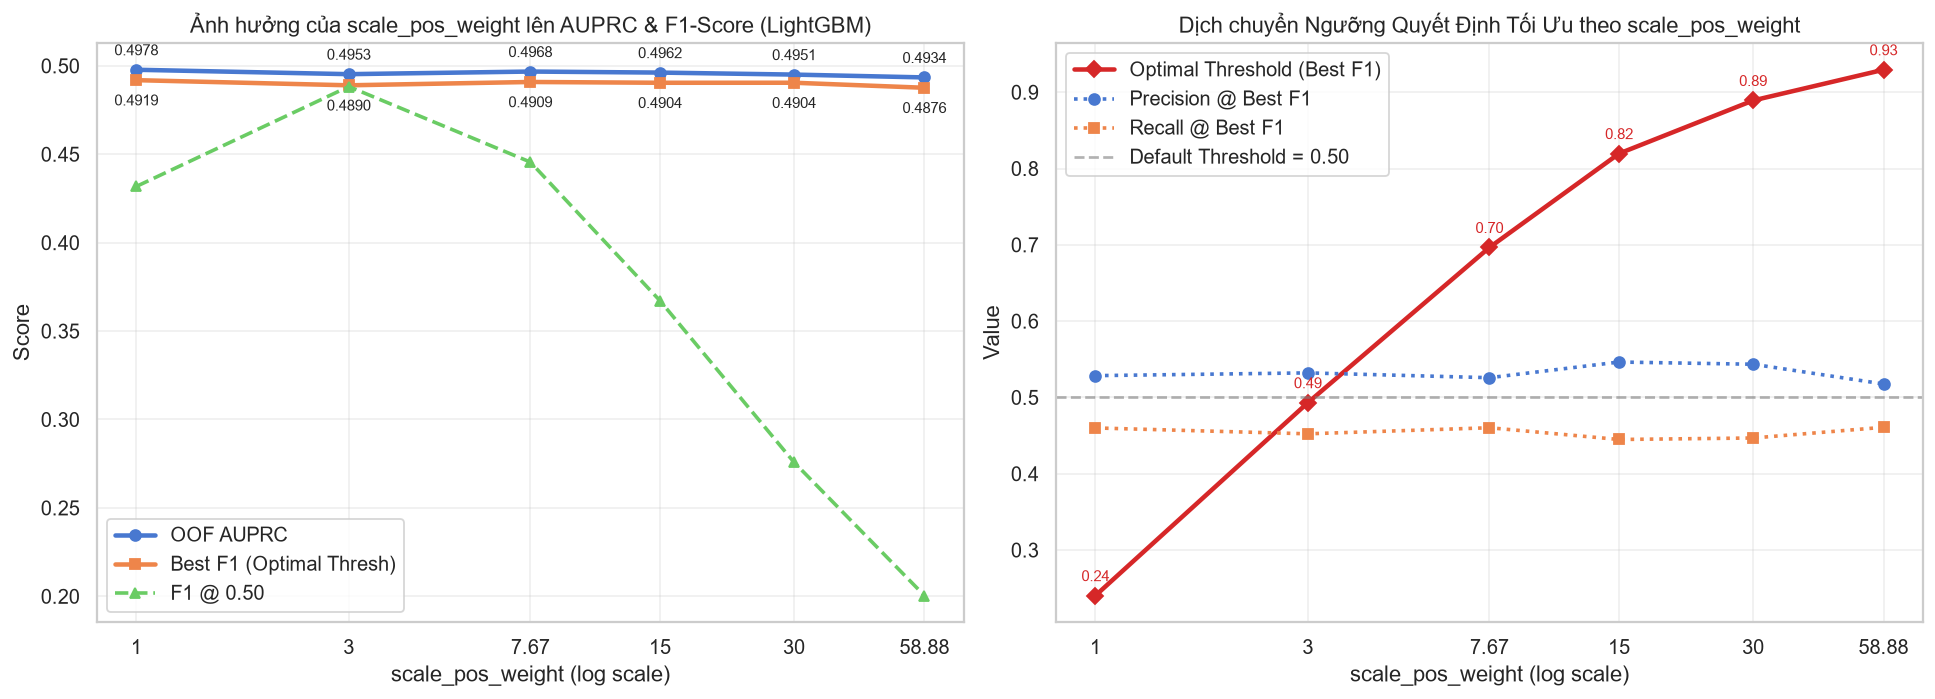

In [10]:
df_spw = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-1A")]).copy()
df_spw["spw"] = [1.0, 3.0, round(SQRT_IR, 3), 15.0, 30.0, round(IR, 3)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: AUPRC, Best F1, F1@0.50
ax = axes[0]
ax.plot(df_spw["spw"], df_spw["OOF_AUPRC"], marker="o", linewidth=2.5, label="OOF AUPRC")
ax.plot(df_spw["spw"], df_spw["Best_F1"], marker="s", linewidth=2.5, label="Best F1 (Optimal Thresh)")
ax.plot(df_spw["spw"], df_spw["F1_at_0.50"], marker="^", linestyle="--", linewidth=2.0, label="F1 @ 0.50")

for _, row in df_spw.iterrows():
    ax.annotate(f"{row['OOF_AUPRC']:.4f}", (row["spw"], row["OOF_AUPRC"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax.annotate(f"{row['Best_F1']:.4f}", (row["spw"], row["Best_F1"]), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=9)

ax.set_xscale("log")
ax.set_xticks(df_spw["spw"])
ax.set_xticklabels([f"{v:.2f}" if v not in (1, 3, 15, 30) else f"{int(v)}" for v in df_spw["spw"]])
ax.set_xlabel("scale_pos_weight (log scale)")
ax.set_ylabel("Score")
ax.set_title("Ảnh hưởng của scale_pos_weight lên AUPRC & F1-Score (LightGBM)")
ax.legend(loc="best")
ax.grid(True, alpha=0.3)

# Right: Threshold Shift + Precision/Recall trade-off
ax2 = axes[1]
ax2.plot(df_spw["spw"], df_spw["Best_Threshold"], marker="D", color="#d62728", linewidth=2.5, label="Optimal Threshold (Best F1)")
ax2.plot(df_spw["spw"], df_spw["Precision_at_Best_F1"], marker="o", linestyle=":", linewidth=2.0, label="Precision @ Best F1")
ax2.plot(df_spw["spw"], df_spw["Recall_at_Best_F1"], marker="s", linestyle=":", linewidth=2.0, label="Recall @ Best F1")
ax2.axhline(0.50, color="gray", linestyle="--", alpha=0.6, label="Default Threshold = 0.50")
for _, row in df_spw.iterrows():
    ax2.annotate(f"{row['Best_Threshold']:.2f}", (row["spw"], row["Best_Threshold"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color="#d62728")

ax2.set_xscale("log")
ax2.set_xticks(df_spw["spw"])
ax2.set_xticklabels([f"{v:.2f}" if v not in (1, 3, 15, 30) else f"{int(v)}" for v in df_spw["spw"]])
ax2.set_xlabel("scale_pos_weight (log scale)")
ax2.set_ylabel("Value")
ax2.set_title("Dịch chuyển Ngưỡng Quyết Định Tối Ưu theo scale_pos_weight")
ax2.legend(loc="best")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4.3. Biểu đồ 2: So Sánh Đường Cong Precision-Recall (Overlaid PR Curves)
So sánh trực quan đường cong Precision-Recall (OOF) của các đại diện mạnh nhất từ mỗi nhóm phương pháp.

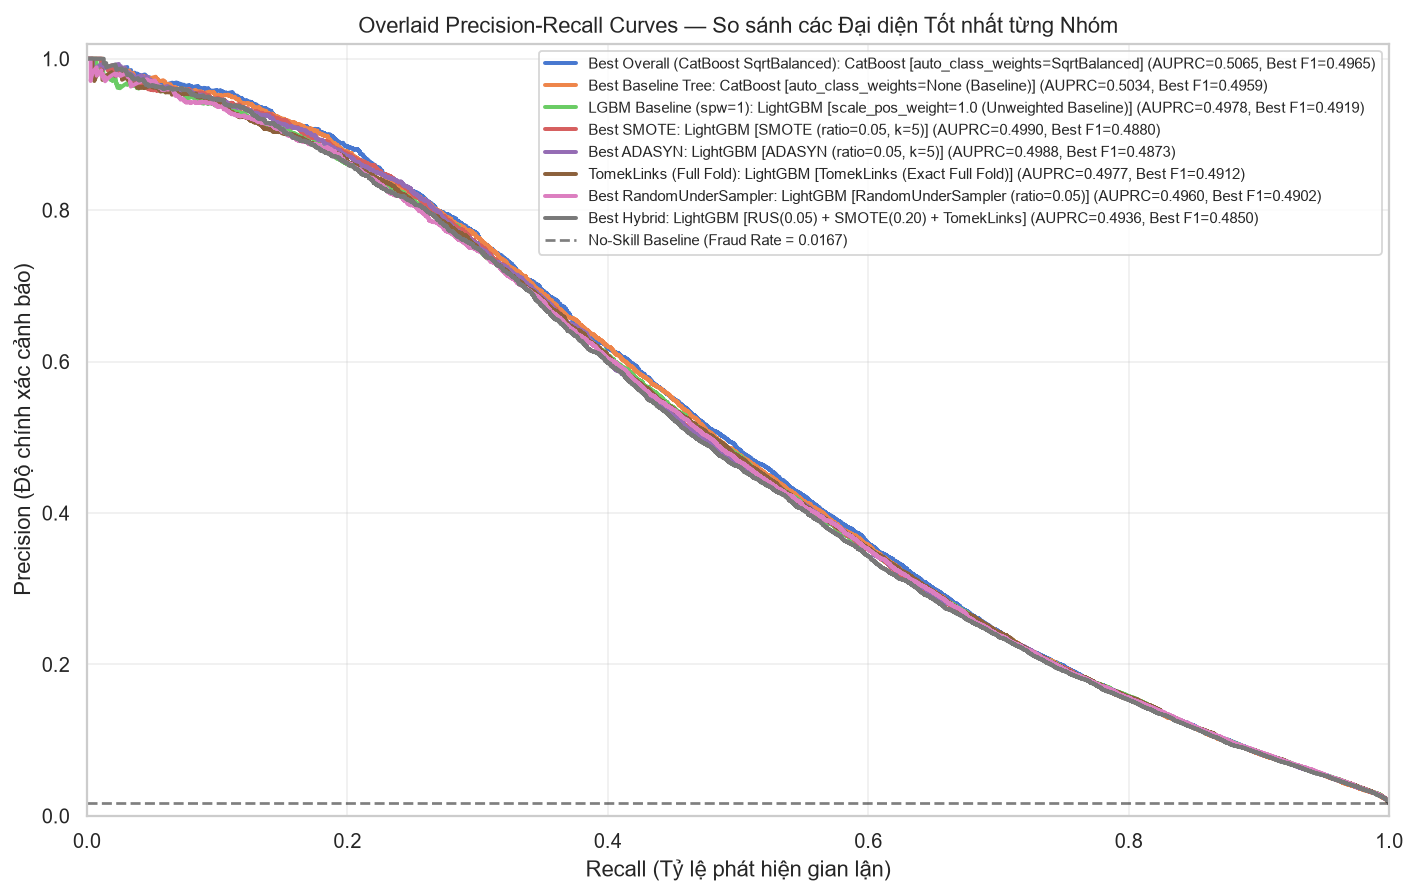

In [11]:
def best_exp_in(filter_fn):
    sub = results_df[results_df.apply(filter_fn, axis=1)]
    return sub.iloc[0] if len(sub) > 0 else None

representatives = [
    ("Best Baseline Tree", best_exp_in(lambda r: r["Category"] == "Baseline")),
    ("LGBM Baseline (spw=1)", results_df[results_df["Experiment_ID"] == "EXP-1A.1"].iloc[0]),
    ("Best scale_pos_weight", best_exp_in(lambda r: r["Category"] == "scale_pos_weight")),
    ("Best RandomUnderSampler", best_exp_in(lambda r: "RandomUnderSampler" in r["Technique_Details"])),
    ("TomekLinks (Full Fold)", results_df[results_df["Experiment_ID"] == "EXP-2A.5"].iloc[0]),
    ("Best SMOTE", best_exp_in(lambda r: r["Technique_Details"].startswith("SMOTE"))),
    ("Best ADASYN", best_exp_in(lambda r: r["Technique_Details"].startswith("ADASYN"))),
    ("Best Hybrid", best_exp_in(lambda r: r["Category"] == "Hybrid")),
]

# Deduplicate by Experiment_ID while preserving order
seen_ids = set()
unique_reps = []
for label, row in representatives:
    if row is not None and row["Experiment_ID"] not in seen_ids:
        seen_ids.add(row["Experiment_ID"])
        unique_reps.append((label, row))

plt.figure(figsize=(11, 7))
for label, row in unique_reps:
    eid = row["Experiment_ID"]
    probs = OOF_STORE[eid]
    prec, rec, _ = precision_recall_curve(y_full, probs)
    plt.plot(
        rec, prec, linewidth=2.2,
        label=f"{label}: {row['Model']} [{row['Technique_Details']}] (AUPRC={row['OOF_AUPRC']:.4f}, Best F1={row['Best_F1']:.4f})"
    )

plt.axhline(y_full.mean(), color="black", linestyle="--", alpha=0.5, label=f"No-Skill Baseline (Fraud Rate = {y_full.mean():.4f})")
plt.xlabel("Recall (Tỷ lệ phát hiện gian lận)")
plt.ylabel("Precision (Độ chính xác cảnh báo)")
plt.title("Overlaid Precision-Recall Curves — So sánh các Đại diện Tốt nhất từng Nhóm")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.legend(loc="upper right", fontsize=8.8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.4. Biểu đồ 3: So Sánh `OOF AUPRC` và `Best F1` Toàn Bộ Thực Nghiệm

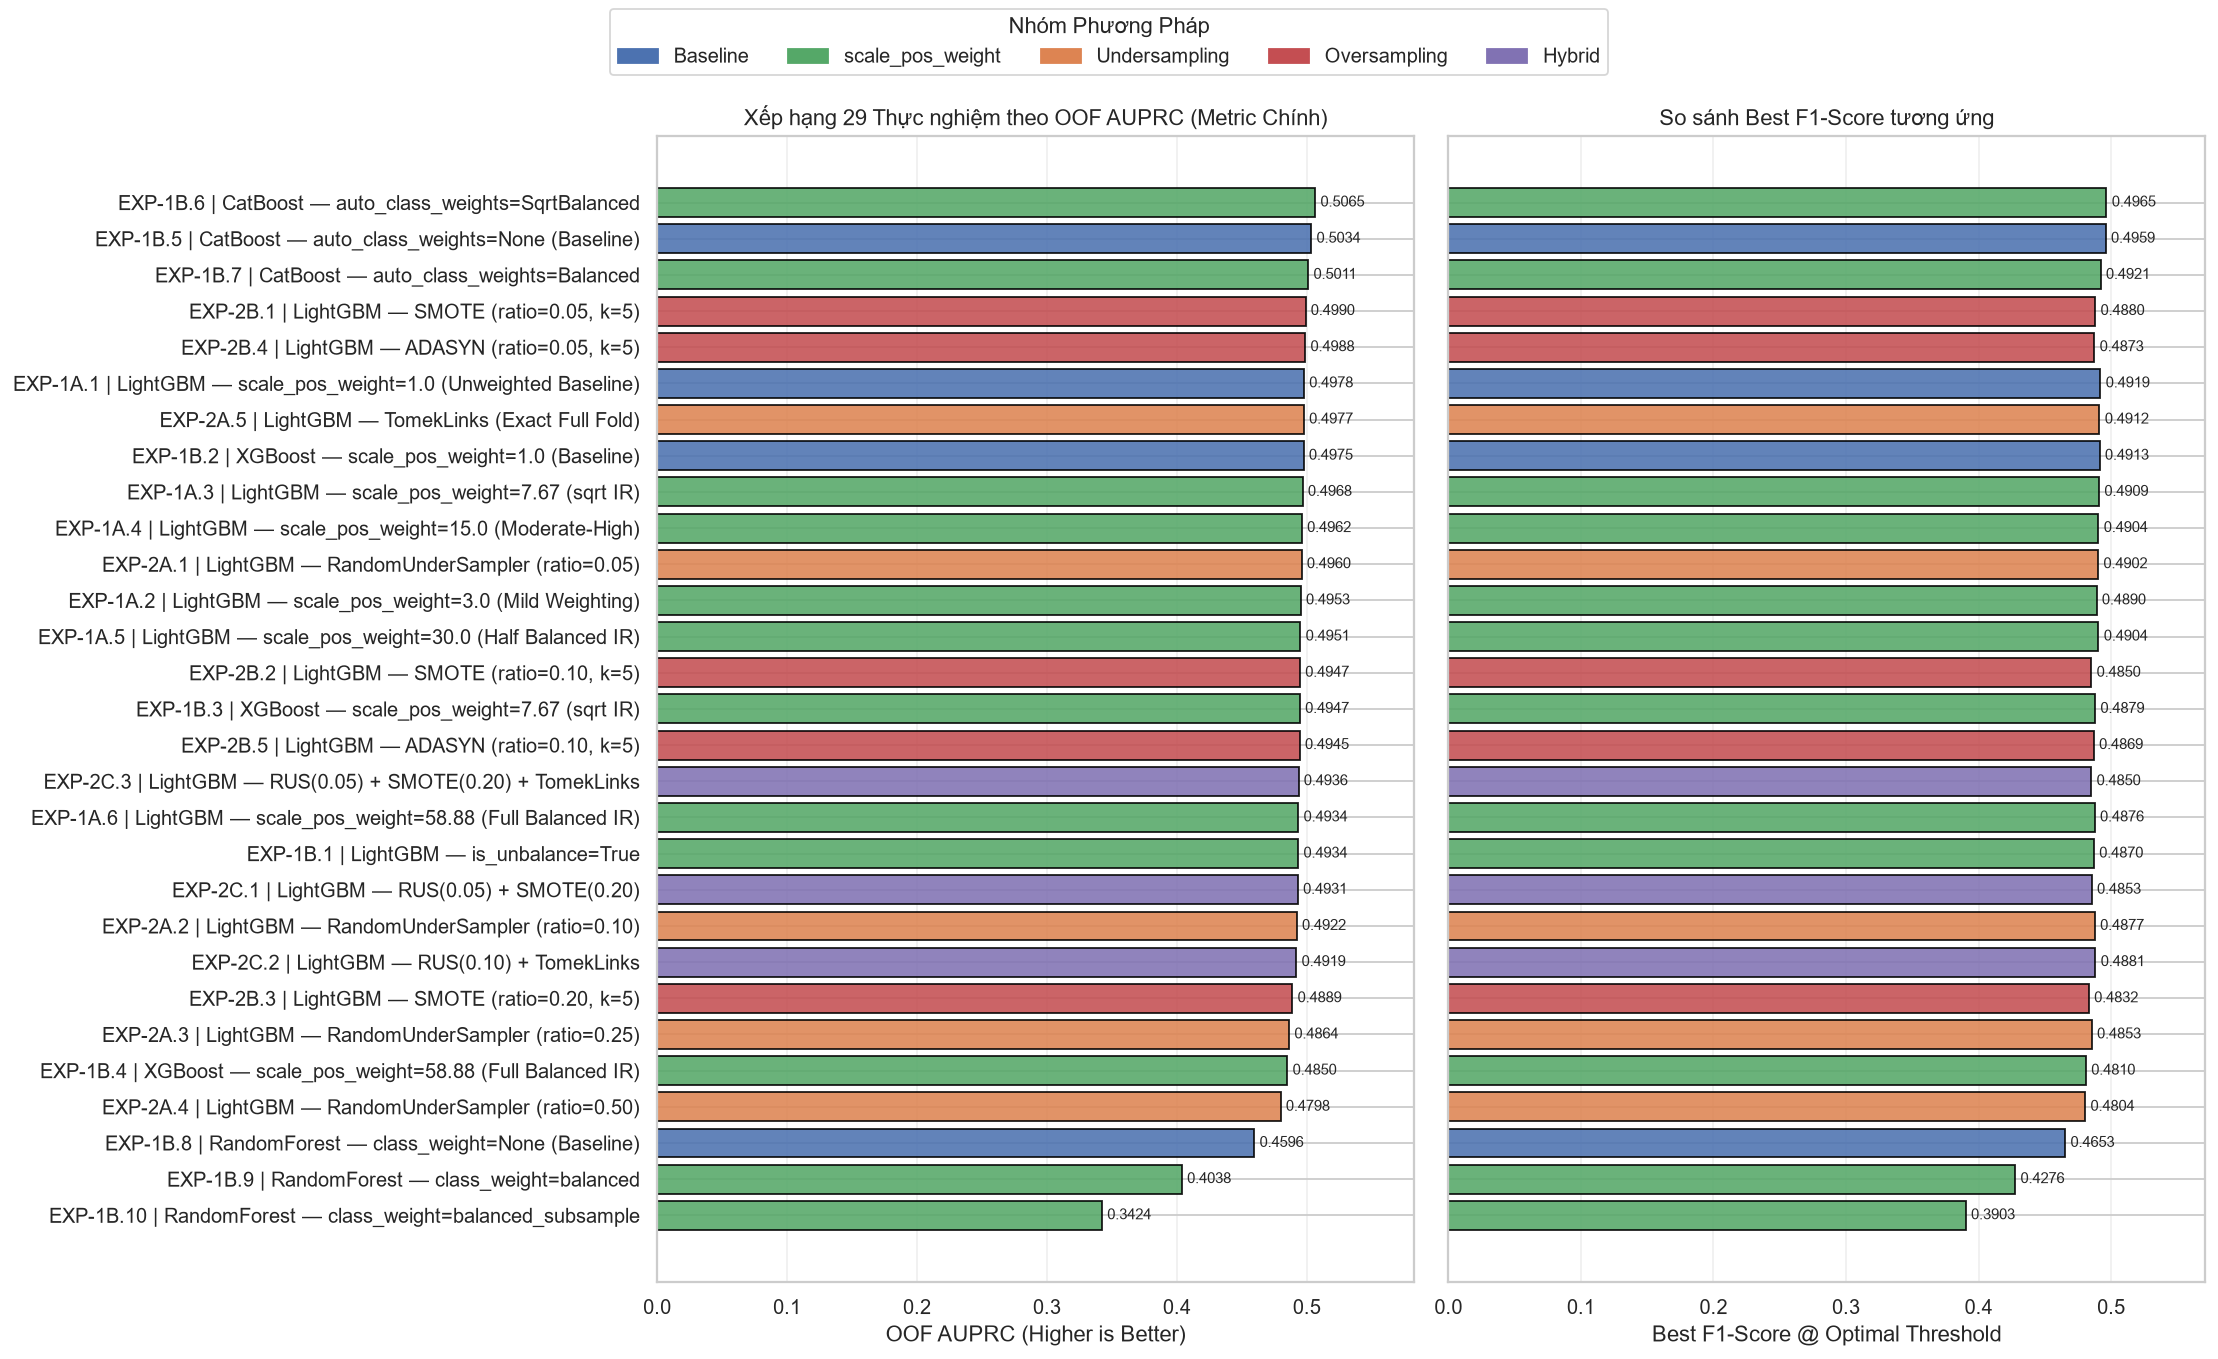

In [12]:
plot_df = results_df.sort_values(by="OOF_AUPRC", ascending=True).copy()
plot_df["Label"] = plot_df["Experiment_ID"] + " | " + plot_df["Model"] + " — " + plot_df["Technique_Details"]

cat_palette = {
    "Baseline": "#4c72b0",
    "scale_pos_weight": "#55a868",
    "Undersampling": "#dd8452",
    "Oversampling": "#c44e52",
    "Hybrid": "#8172b3",
}
colors = [cat_palette[c] for c in plot_df["Category"]]

fig, axes = plt.subplots(1, 2, figsize=(17, 10), sharey=True)

# Left: OOF AUPRC
axes[0].barh(plot_df["Label"], plot_df["OOF_AUPRC"], color=colors, edgecolor="black", alpha=0.88)
for i, v in enumerate(plot_df["OOF_AUPRC"]):
    axes[0].text(v + 0.003, i, f"{v:.4f}", va="center", fontsize=8.5)
axes[0].set_xlabel("OOF AUPRC (Higher is Better)")
axes[0].set_title("Xếp hạng theo OOF AUPRC (Metric Chính)")
axes[0].set_xlim(0, plot_df["OOF_AUPRC"].max() * 1.15)
axes[0].grid(axis="x", alpha=0.3)

# Right: Best F1
axes[1].barh(plot_df["Label"], plot_df["Best_F1"], color=colors, edgecolor="black", alpha=0.88)
for i, v in enumerate(plot_df["Best_F1"]):
    axes[1].text(v + 0.003, i, f"{v:.4f}", va="center", fontsize=8.5)
axes[1].set_xlabel("Best F1-Score @ Optimal Threshold")
axes[1].set_title("So sánh Best F1-Score tương ứng")
axes[1].set_xlim(0, plot_df["Best_F1"].max() * 1.15)
axes[1].grid(axis="x", alpha=0.3)

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=col, edgecolor="black") for col in cat_palette.values()]
fig.legend(handles, cat_palette.keys(), loc="upper center", ncol=5, frameon=True, title="Nhóm Phương Pháp")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### 4.5. Biểu đồ 4: Dịch Chuyển Phân Phối Xác Suất (Probability Shift) & Ngưỡng Tối Ưu
So sánh phân phối xác suất dự đoán trên tập OOF giữa mô hình gốc (`spw=1.0`), `scale_pos_weight` (`7.67`, `58.88`), `SMOTE (0.20)`, và `RandomUnderSampler (0.50)` để lý giải sự chênh lệch giữa `F1 @ 0.50` và `Best F1`.

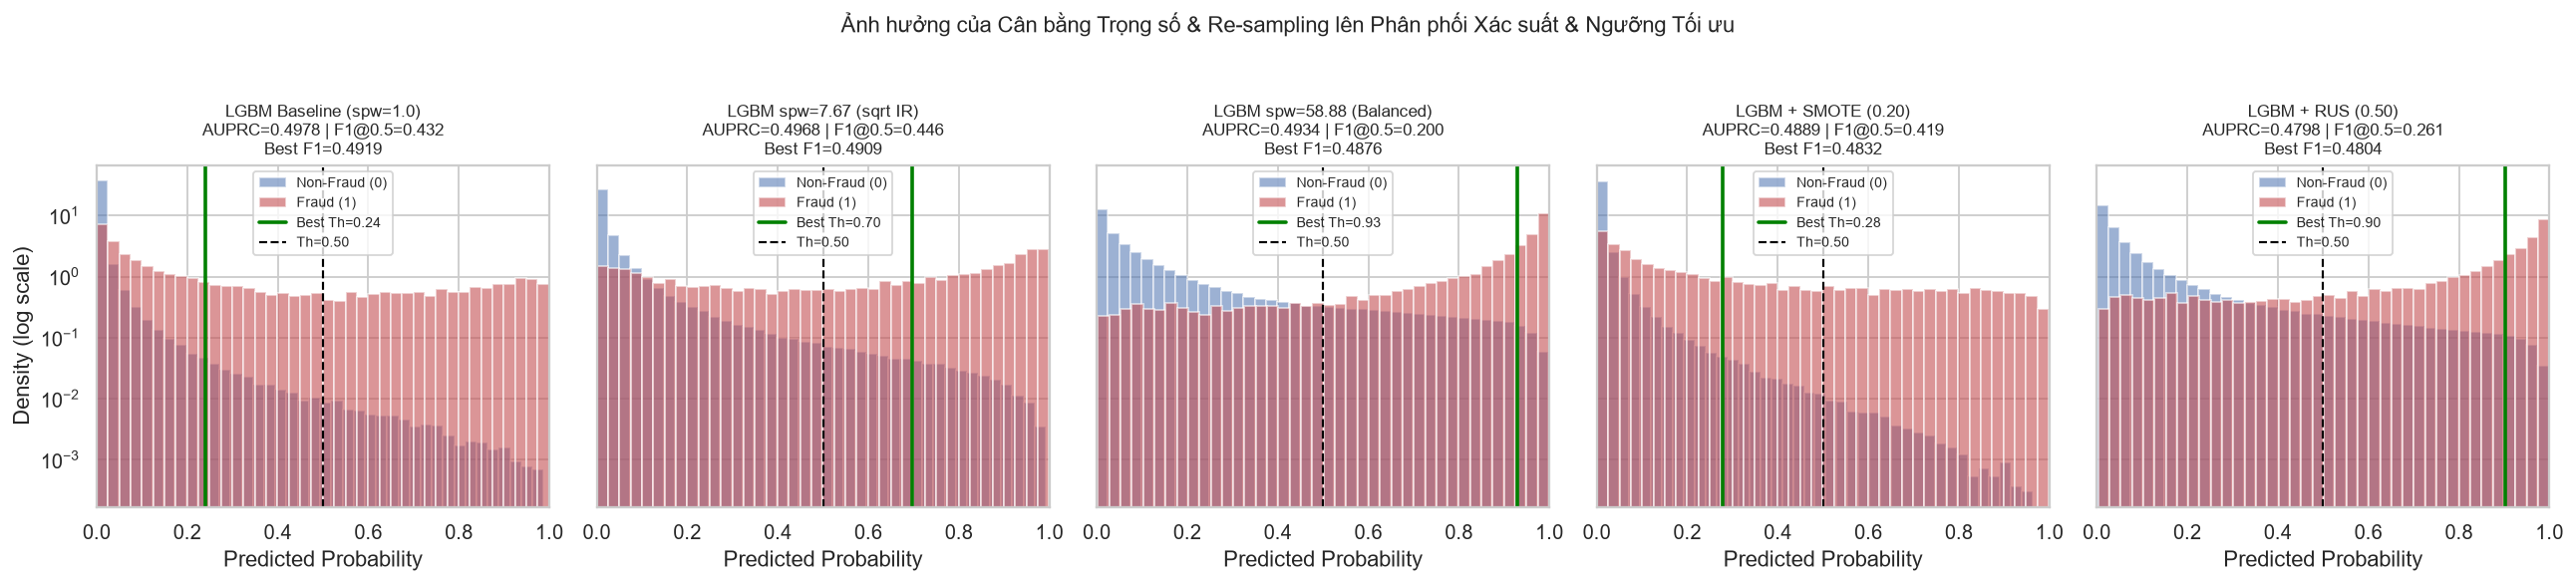

In [13]:
shift_exps = [
    ("EXP-1A.1", "LGBM Baseline (spw=1.0)"),
    ("EXP-1A.3", f"LGBM spw={SQRT_IR:.2f} (sqrt IR)"),
    ("EXP-1A.6", f"LGBM spw={IR:.2f} (Balanced)"),
    ("EXP-2B.3", "LGBM + SMOTE (0.20)"),
    ("EXP-2A.4", "LGBM + RUS (0.50)"),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 4.2), sharey=True)
for ax, (eid, title) in zip(axes, shift_exps):
    probs = OOF_STORE[eid]
    row = results_df[results_df["Experiment_ID"] == eid].iloc[0]
    ax.hist(probs[y_full == 0], bins=40, density=True, alpha=0.55, color="#4c72b0", label="Non-Fraud (0)")
    ax.hist(probs[y_full == 1], bins=40, density=True, alpha=0.60, color="#c44e52", label="Fraud (1)")
    ax.axvline(row["Best_Threshold"], color="green", linestyle="-", linewidth=2, label=f"Best Th={row['Best_Threshold']:.2f}")
    ax.axvline(0.50, color="black", linestyle="--", linewidth=1.2, label="Th=0.50")
    ax.set_yscale("log")
    ax.set_xlim(0, 1)
    ax.set_title(f"{title}\nAUPRC={row['OOF_AUPRC']:.4f} | F1@0.5={row['F1_at_0.50']:.3f}\nBest F1={row['Best_F1']:.4f}", fontsize=9.5)
    ax.set_xlabel("Predicted Probability")
    ax.legend(fontsize=7.5, loc="upper center")
axes[0].set_ylabel("Density (log scale)")
plt.suptitle("Ảnh hưởng của Cân bằng Trọng số & Re-sampling lên Phân phối Xác suất & Ngưỡng Tối ưu", y=1.04, fontsize=12)
plt.tight_layout()
plt.show()

---
## 5. Tổng Kết & Khuyến Nghị Chiến Lược

Qua **29 thực nghiệm Stratified 5-Fold CV** chống rò rỉ dữ liệu tuyệt đối trên toàn bộ `699,960` giao dịch (tỷ lệ gian lận `1.670%`, $\text{IR} \approx 58.88$), các kết luận cốt lõi rút ra như sau:

### 5.1. Đánh giá Giai đoạn 1 — `scale_pos_weight` / `class_weight` trên các mô hình dạng cây
1. **Hiệu quả nổi bật của `CatBoost` + `SqrtBalanced` (Top 1 toàn bảng):**
   - `CatBoost (auto_class_weights="SqrtBalanced")` đạt **OOF AUPRC = `0.5065`** (`Mean Fold = 0.5067 ± 0.0115`), **ROC-AUC = `0.9454`**, **Best F1 = `0.4965`** (@ threshold `0.6855`), vượt trội cả `CatBoost Baseline` (`0.5034`, `+0.0031` AUPRC đồng nhất trên cả 5 fold) và vượt xa Baseline LogisticRegression ban đầu trong `validation_pipeline.ipynb` (`AUPRC = 0.1909`, `Best F1 = 0.2563`).
2. **Trọng số quá lớn (`Full Balanced ~58.88` / `is_unbalance=True`) gây suy giảm AUPRC trên cả 4 họ mô hình:**
   - **CatBoost:** `SqrtBalanced (0.5065)` > `None (0.5034)` > `Balanced (0.5011)`.
   - **LightGBM:** `spw=1.0 (0.4978)` > `spw=7.67 (0.4968)` > `spw=15 (0.4962)` > `spw=30 (0.4951)` > `spw=58.88 (0.4934)` $\approx$ `is_unbalance=True (0.4934)`.
   - **XGBoost:** `spw=1.0 (0.4975)` > `spw=7.67 (0.4947)` > `spw=58.88 (0.4850)` (sụt giảm `-0.0125`).
   - **Random Forest:** `None (0.4596)` > `balanced (0.4038)` > `balanced_subsample (0.3424)` (sụt giảm nghiêm trọng `-0.1172` do phân chia nhánh Gini bị lệch mạnh bởi trọng số `~59x`).
3. **Bẫy đánh giá bằng ngưỡng mặc định `0.50` (Threshold Shift):**
   - Khi tăng `scale_pos_weight` từ `1.0` $\rightarrow$ `58.88` trên LightGBM, ngưỡng tối ưu dịch chuyển mạnh từ `0.2403` $\rightarrow$ `0.9294`, khiến `F1 @ 0.50` lao dốc từ `0.4883` (tại `spw=3.0`, nơi ngưỡng tối ưu trùng sát `0.4931`) xuống còn `0.2004` tại `spw=58.88`. Do đó **bắt buộc phải đánh giá bằng AUPRC và tối ưu ngưỡng quyết định (`Best Threshold`)** thay vì dùng cứng ngưỡng `0.50`.

### 5.2. Đánh giá Giai đoạn 2 — Các kỹ thuật Re-sampling trên LightGBM (`spw=1.0`)
1. **Oversampling liều nhẹ (`ratio=0.05`) cải thiện AUPRC cho LightGBM, nhưng tỷ lệ cao gây nhiễu:**
   - **SMOTE (`ratio=0.05`)** đạt **OOF AUPRC = `0.4990`** (`+0.0012` so với LightGBM gốc `0.4978`) — cao nhất trong toàn bộ nhóm LightGBM & Re-sampling!
   - **ADASYN (`ratio=0.05`)** đạt **OOF AUPRC = `0.4988`** (`+0.0010` so với gốc), bám sát SMOTE nhưng hơi kém hơn một chút do tập trung sinh mẫu ở vùng biên nhiều nhiễu.
   - Khi tăng tỷ lệ oversampling lên `0.10` và `0.20`, cả SMOTE (`0.4947` $\rightarrow$ `0.4889`) lẫn ADASYN (`0.4945`) đều suy giảm rõ rệt do sinh quá nhiều mẫu giả nội suy gây overfitting.
2. **Undersampling (`RandomUnderSampler` & `TomekLinks`):**
   - **TomekLinks (Exact Full Fold via `FastTomekLinks`):** Loại bỏ ~1,861 mẫu Non-Fraud chồng lấn ở biên mỗi fold, đạt **OOF ROC-AUC cao nhất toàn bảng (`0.9456`)** và giữ nguyên **Mean Fold AUPRC = `0.4982`** (ngang/nhỉnh nhẹ so với gốc `0.4981`).
   - **RandomUnderSampler:** Mất thông tin lớp đa số tỷ lệ thuận với mức cắt giảm: `ratio=0.05 (0.4960)` $\rightarrow$ `0.10 (0.4922)` $\rightarrow$ `0.25 (0.4864)` $\rightarrow$ `0.50 (0.4798)`. Tuy nhiên, `RUS (0.05)` giúp **tăng tốc huấn luyện ~30%** (`57.8s` vs `81.7s`) và đạt **`F1 @ 0.50 = 0.4900`** cao nhất toàn bộ 29 thực nghiệm (vì `Best Threshold = 0.5050` gần như khớp tuyệt đối với `0.50`).
3. **Hybrid (`RUS + SMOTE + TomekLinks`):**
   - Kết hợp `TomekLinks` sau `RUS(0.05) + SMOTE(0.20)` cải thiện AUPRC từ `0.4931` $\rightarrow$ `0.4936` (`+0.0005`), đồng thời `RUS(0.10) + TomekLinks` cho độ ổn định giữa các fold tốt nhất (`Std = 0.0103`) với thời gian chạy rất nhanh (`18.3s` cho cả 5 folds).

### 5.3. Khuyến nghị triển khai cho các giai đoạn tiếp theo
- **Lựa chọn ưu tiên số 1 (Hiệu năng cao nhất):** Dùng **CatBoost với `auto_class_weights="SqrtBalanced"`** (hoặc LightGBM/XGBoost với trọng số nhẹ `1.0` đến $\sqrt{\text{IR}}$ kết hợp tinh chỉnh ngưỡng OOF — **không** dùng `Balanced ~58.88`).
- **Lựa chọn Re-sampling bổ sung cho Ensemble đa dạng:** Kết hợp thêm một mô hình nhánh huấn luyện với **`SMOTE (ratio=0.05)`** (`OOF AUPRC = 0.4990`) hoặc **`TomekLinks`** (`ROC-AUC = 0.9456`) thông qua module dùng chung `imbalance_pipeline.py` để tăng độ đa dạng (diversity) khi Blending / Stacking ở giai đoạn cuối.
- **Lựa chọn tối ưu tốc độ khi Feature Engineering / Hyperparameter Tuning:** Dùng `RandomUnderSampler(sampling_strategy=0.05)` giúp giảm kích thước tập train ~3 lần để thử nghiệm nhanh, sau đó huấn luyện lại trên toàn bộ tập dữ liệu với `SqrtBalanced` / `SMOTE(0.05)`.
